# Did Wembanyama need a different playoff shot diet?

Joseph Smarrelli · September 2026 · 2026 playoff review

Against opponents with a regular-season comparison sample, Victor Wembanyama took a larger share of his playoff attempts at the rim and from three, and fewer from midrange. His field-goal scoring still fell. The accounting points toward lower conversion within locations as the larger contributor in this sample.

That makes the first review question more specific than “Should he shoot fewer threes?” It asks what changed about the attempts inside each part of the floor.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import playoff_diet
summary = playoff_diet.run()
from src import figures
figures.run()
summary

{'unsupported_opponents_excluded': ['POR'],
 'unsupported_opponent_attempts_excluded': 48,
 'inconsistent_zone_attempts_excluded': 1,
 'regular_games': 9,
 'regular_attempts': 133,
 'playoff_games': 18,
 'playoff_attempts': 314,
 'opponents': ['MIN', 'NYK', 'OKC'],
 'playoff_last_date': '2026-06-13',
 'matched_regular_ppa': np.float64(1.204191201335941),
 'playoff_ppa': np.float64(1.0350318471337578),
 'raw_matched_regular_ppa': np.float64(1.1804511278195489),
 'components': [{'component': 'Shot-location mix',
   'estimate': 0.040373142803564466,
   'lower': -0.001963572204367843,
   'upper': 0.10289477449961962},
  {'component': 'Within-zone conversion',
   'estimate': -0.20953249700574747,
   'lower': -0.4629821164890986,
   'upper': -0.01114551240923344},
  {'component': 'Total FG scoring change',
   'estimate': -0.1691593542021832,
   'lower': -0.4050025577609504,
   'upper': 0.037440173362776746}],
 'bootstrap': '2,000 independent game resamples within each phase and opponent; pla

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/playoff_decomposition.csv')

,component,estimate,lower,upper
0,Shot-location mix,0.040373,-0.001964,0.102895
1,Within-zone conversion,-0.209532,-0.462982,-0.011146
2,Total FG scoring change,-0.169159,-0.405003,0.037440


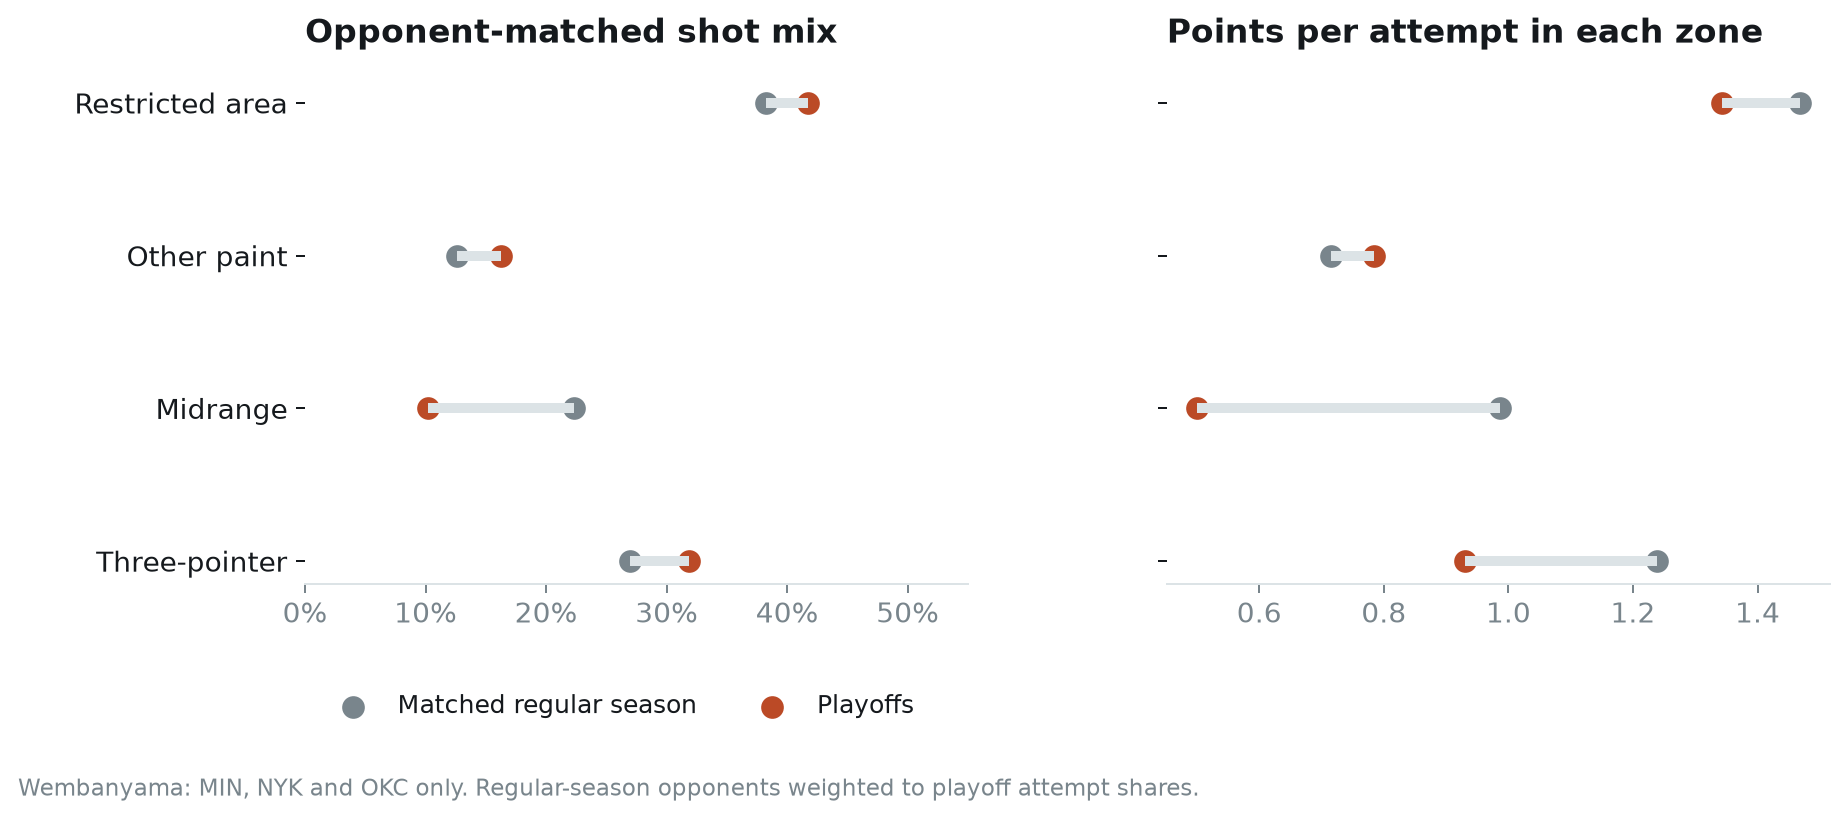

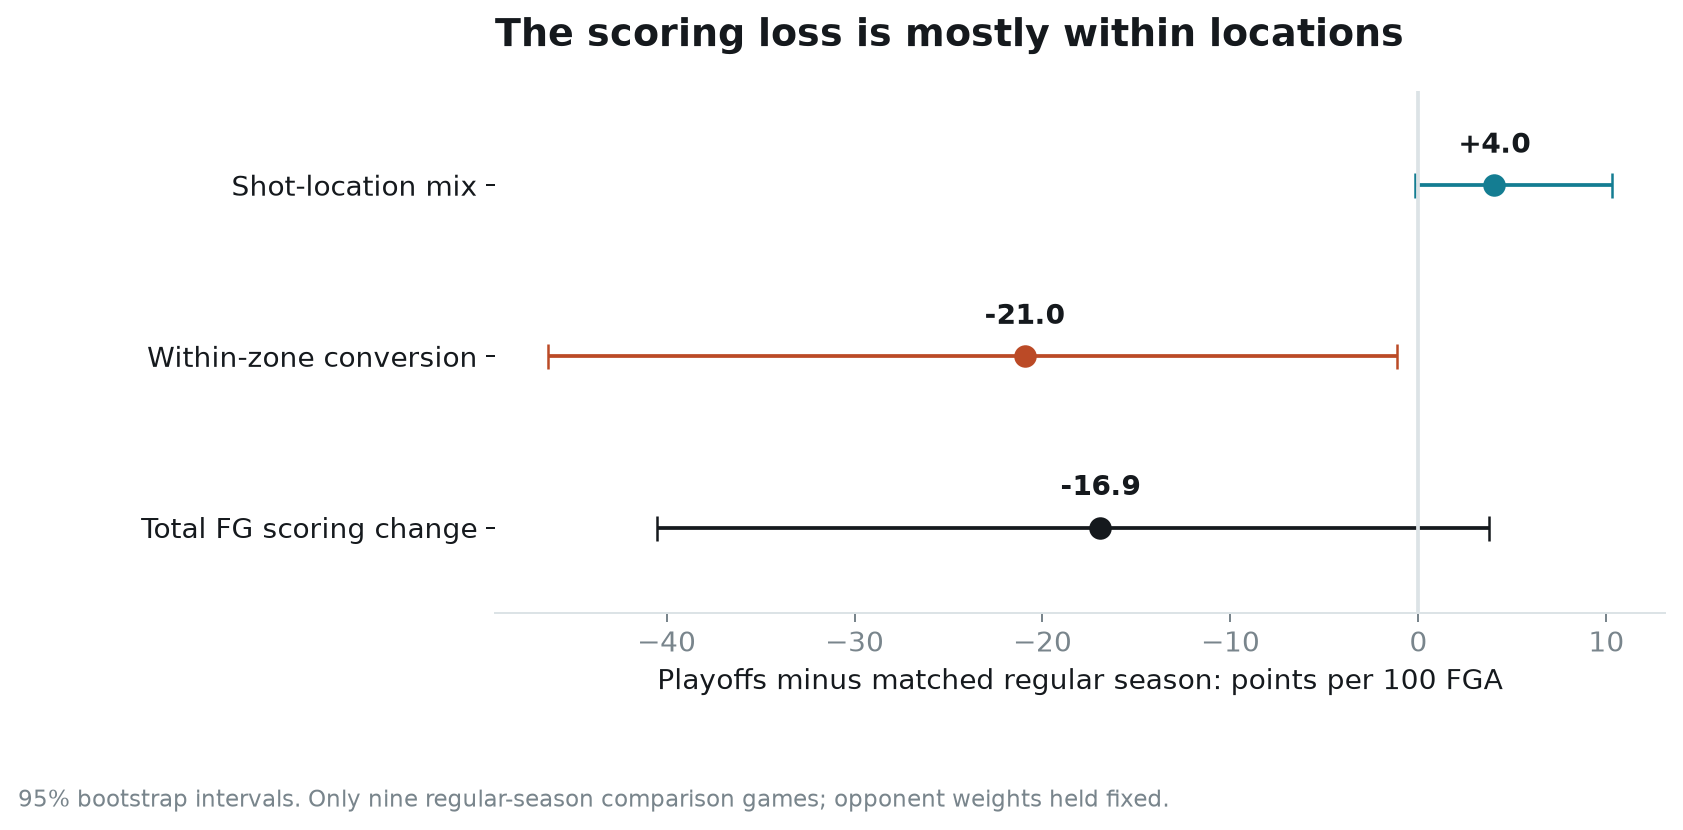

In [3]:
display(Image(filename='figures/playoff_profile.png'))
display(Image(filename='figures/playoff_components.png'))

## Verify the accounting
Recalculate the decomposition from matched shots, then inspect the opponent sample sizes and full-season context.

In [4]:
from src.playoff_diet import weighted_profile, decomposition
d = pd.read_csv('data/playoff_shots.csv.gz')
r = d[d.phase.eq('Matched regular season')]
p = d[d.phase.eq('Playoffs')]
weights = p.opponent.value_counts(normalize=True).sort_index()
a, b = weighted_profile(r, weights), weighted_profile(p, weights)
parts = decomposition(a, b)
assert abs(parts[0] + parts[1] - parts[2]) < 1e-12
display(pd.Series(parts * 100, index=['Location mix', 'Within-zone conversion', 'Total']))
display(pd.read_csv('results/playoff_opponents.csv'))
display(pd.read_csv('results/wemby_regular_trend.csv'))

Location mix               4.037314
Within-zone conversion   -20.953250
Total                    -16.915935
dtype: float64

,opponent,regular_games,regular_attempts,playoff_games,playoff_attempts,weight,regular_ppa,playoff_ppa
0,MIN,2,41,6,82,0.261146,1.146341,1.109756
1,NYK,2,29,5,104,0.331210,1.344828,0.932692
2,OKC,5,63,7,128,0.407643,1.126984,1.070312


,season,attempts,games,rim_share,three_share,ppa
0,2023-24,1186,71,0.333895,0.332209,1.037099
1,2024-25,857,46,0.241540,0.470245,1.117853
2,2025-26,1080,64,0.357407,0.324074,1.137037


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.